<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_08_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 8.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

### Praktikum 8.2 Import Dataset

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

### Praktikum 8.3 Preprocessing

In [3]:
# SVM sangat sensitif terhadap skala fitur, scaling WAJIB dilakukan
pipeline = Pipeline([("scaler", StandardScaler()), ("svm", SVC())])

### Praktikum 8.4 Training Model dengan GridSearchCV

In [4]:
param_grid = {"svm__C": [0.1, 1, 10, 100],
              "svm__gamma": [0.001, 0.01, 0.1, 1],
              "svm__kernel": ["rbf", "linear"]}
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Parameter terbaik:", grid_search.best_params_)
print("F1-Score terbaik (CV):", round(grid_search.best_score_, 3))

Parameter terbaik: {'svm__C': 10, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}
F1-Score terbaik (CV): 0.984


### Praktikum 8.5 Evaluasi

In [5]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
print("Akurasi Test:", round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))

Akurasi Test: 0.982
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### Praktikum 8.6 Visualisasi

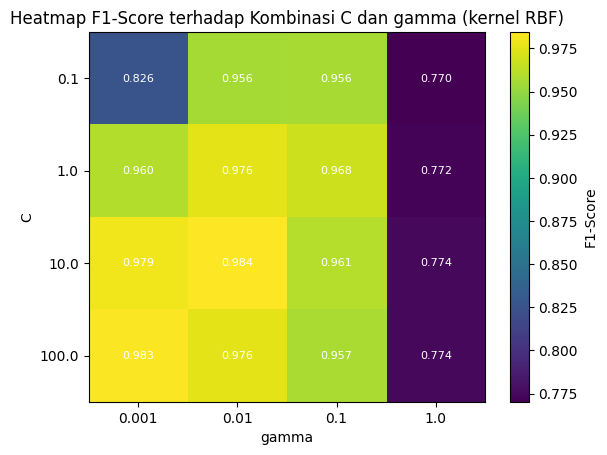

In [6]:
hasil = pd.DataFrame(grid_search.cv_results_)
hasil_rbf = hasil[hasil["param_svm__kernel"] == "rbf"]          # hanya kernel RBF
pivot = hasil_rbf.pivot_table(values="mean_test_score", index="param_svm__C", columns="param_svm__gamma")
plt.imshow(pivot, cmap="viridis", aspect="auto")
plt.xticks(range(len(pivot.columns)), pivot.columns)
plt.yticks(range(len(pivot.index)), pivot.index)
plt.xlabel("gamma"); plt.ylabel("C")
plt.title("Heatmap F1-Score terhadap Kombinasi C dan gamma (kernel RBF)")
plt.colorbar(label="F1-Score")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        plt.text(j, i, f"{pivot.values[i, j]:.3f}", ha="center", va="center", color="w", fontsize=8)
plt.show()

### Praktikum 1 — Perbandingan Kernel (Praktikum 8.7)

In [7]:
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"Kernel {kernel}: akurasi = {acc:.3f}")

Kernel linear: akurasi = 0.974
Kernel poly: akurasi = 0.912
Kernel rbf: akurasi = 0.982


In [8]:
# Pelengkap: CV 5-fold pada train set + jumlah support vector (parameter default tiap kernel)
from sklearn.model_selection import cross_val_score, StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for kernel in ["linear", "poly", "rbf"]:
    model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(kernel=kernel))])
    cv = cross_val_score(model, X_train, y_train, cv=skf)
    model.fit(X_train, y_train)
    baris.append({"Kernel": kernel, "Akurasi CV": cv.mean(), "Std CV": cv.std(),
                  "Akurasi Test": accuracy_score(y_test, model.predict(X_test)),
                  "Jumlah support vector": int(model.named_steps["svm"].n_support_.sum())})
pd.DataFrame(baris).set_index("Kernel").round(3)

,Akurasi CV,Std CV,Akurasi Test,Jumlah support vector
Kernel,,,,
linear,0.965,0.016,0.974,32
poly,0.897,0.033,0.912,145
rbf,0.969,0.015,0.982,97


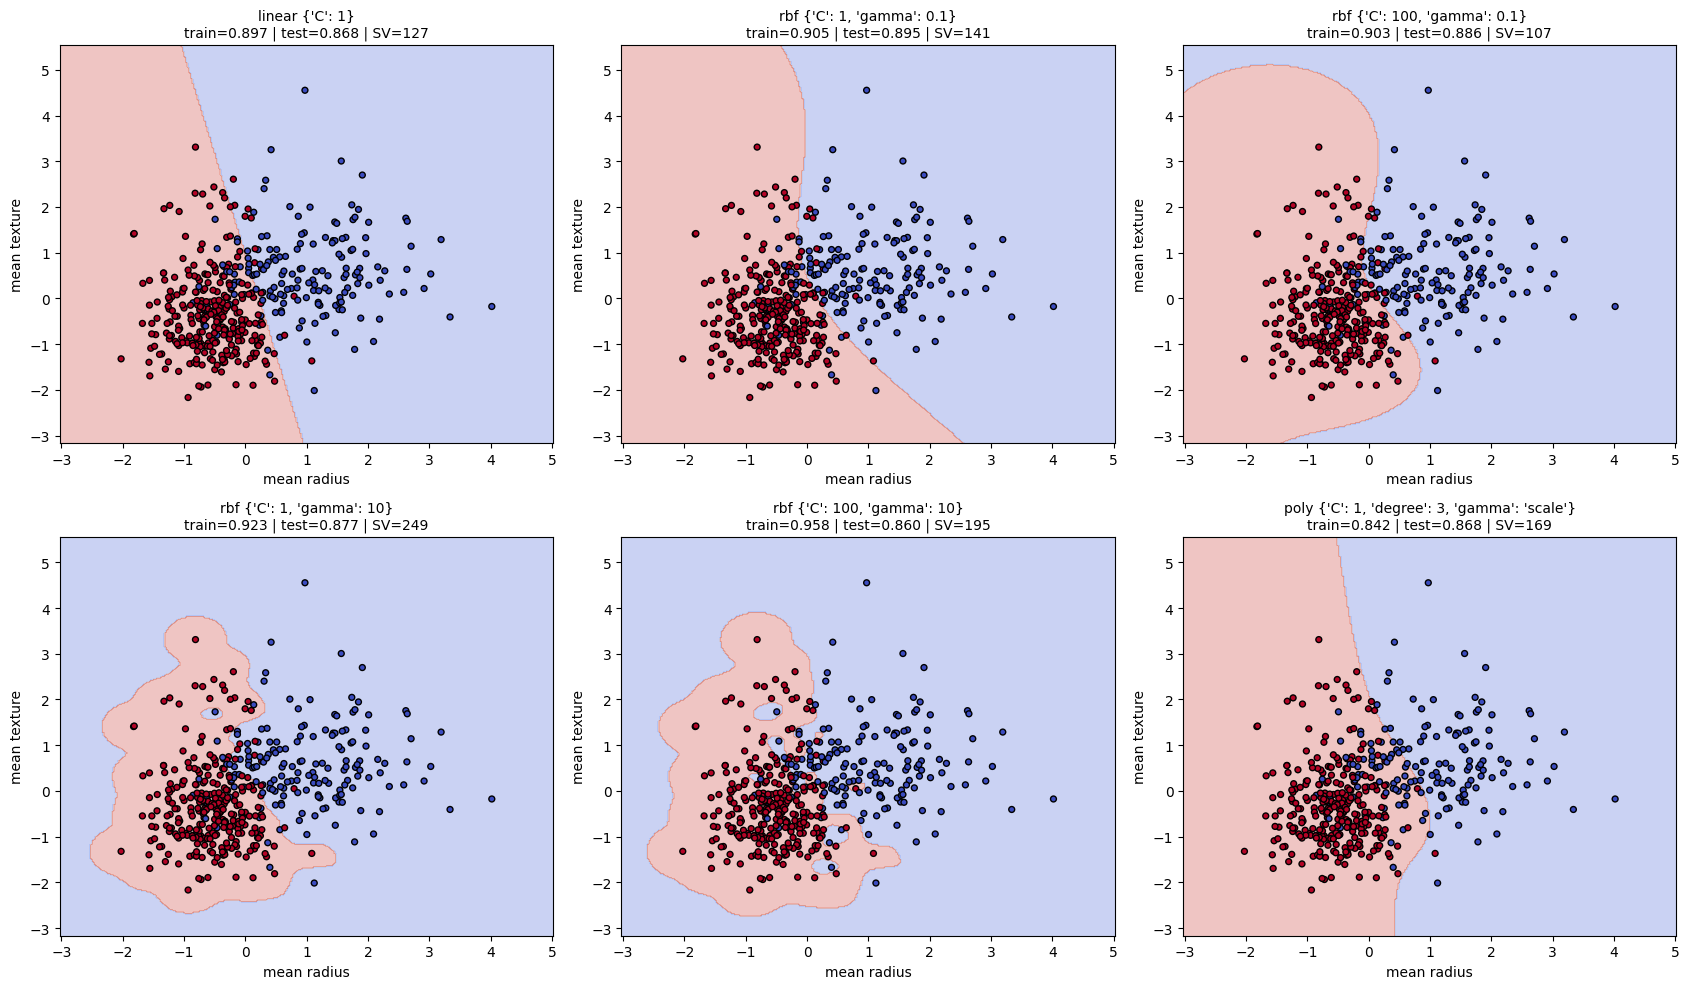

,kernel,parameter,akurasi train,akurasi test,gap,jumlah SV
0,linear,{'C': 1},0.897,0.868,0.028,127
1,rbf,"{'C': 1, 'gamma': 0.1}",0.905,0.895,0.011,141
2,rbf,"{'C': 100, 'gamma': 0.1}",0.903,0.886,0.017,107
3,rbf,"{'C': 1, 'gamma': 10}",0.923,0.877,0.046,249
4,rbf,"{'C': 100, 'gamma': 10}",0.958,0.860,0.099,195
5,poly,"{'C': 1, 'degree': 3, 'gamma': 'scale'}",0.842,0.868,-0.027,169


In [9]:
from sklearn.inspection import DecisionBoundaryDisplay

fitur2 = ["mean radius", "mean texture"]
X2 = X[fitur2]
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42, stratify=y)
sc2 = StandardScaler().fit(X2_train)
X2_tr, X2_te = sc2.transform(X2_train), sc2.transform(X2_test)

konfigurasi = [("linear", dict(C=1)),
               ("rbf", dict(C=1, gamma=0.1)),
               ("rbf", dict(C=100, gamma=0.1)),
               ("rbf", dict(C=1, gamma=10)),
               ("rbf", dict(C=100, gamma=10)),
               ("poly", dict(C=1, degree=3, gamma="scale"))]

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
ringkas = []
for ax, (kernel, params) in zip(axes.ravel(), konfigurasi):
    clf = SVC(kernel=kernel, **params).fit(X2_tr, y2_train)
    DecisionBoundaryDisplay.from_estimator(clf, X2_tr, response_method="predict", cmap="coolwarm",
                                           alpha=0.3, ax=ax, grid_resolution=300,
                                           xlabel=fitur2[0], ylabel=fitur2[1])
    ax.scatter(X2_tr[:, 0], X2_tr[:, 1], c=y2_train, cmap="coolwarm", edgecolor="k", s=18)
    acc_tr, acc_te = clf.score(X2_tr, y2_train), clf.score(X2_te, y2_test)
    ax.set_title(f"{kernel} {params}\ntrain={acc_tr:.3f} | test={acc_te:.3f} | SV={clf.n_support_.sum()}", fontsize=10)
    ringkas.append({"kernel": kernel, "parameter": str(params), "akurasi train": acc_tr,
                    "akurasi test": acc_te, "gap": acc_tr - acc_te, "jumlah SV": int(clf.n_support_.sum())})
plt.tight_layout(); plt.show()
pd.DataFrame(ringkas).round(3)